In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv(
    "../data/raw/PS_20174392719_1491204439457_log.csv"
)

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
# Remove identifiers and post-transaction information

columns_to_drop = [
    "nameOrig",
    "nameDest",
    "isFlaggedFraud",
    "newbalanceOrig",
    "newbalanceDest"
]

df = df.drop(columns=columns_to_drop)

# Separate features and target

X = df.drop(columns=["isFraud"])

y = df["isFraud"]

# Convert transaction type into numerical columns

X = pd.get_dummies(
    X,
    columns=["type"],
    dtype=int
)

print("Features:", X.shape)

print("Target:", y.shape)

Features: (6362620, 9)
Target: (6362620,)


In [4]:
train_end = df["step"].quantile(0.70)

validation_end = df["step"].quantile(0.85)

train_mask = df["step"] <= train_end

validation_mask = (
    (df["step"] > train_end) &
    (df["step"] <= validation_end)
)

test_mask = df["step"] > validation_end

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (4463587, 9)
Validation: (980416, 9)
Testing: (918617, 9)


In [5]:
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=42
)

print("Training sample:", X_train_sample.shape)

print("\nFraud distribution:")

print(y_train_sample.value_counts())

Training sample: (500000, 9)

Fraud distribution:
isFraud
0    499592
1       408
Name: count, dtype: int64


In [6]:
# Calculate class imbalance ratio

negative_count = (y_train_sample == 0).sum()

positive_count = (y_train_sample == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate transactions:", negative_count)
print("Fraudulent transactions:", positive_count)

print("Scale positive weight:", scale_pos_weight)

Legitimate transactions: 499592
Fraudulent transactions: 408
Scale positive weight: 1224.4901960784314


In [7]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

In [8]:
xgb_model.fit(
    X_train_sample,
    y_train_sample,
    verbose=True
)

print("XGBoost training completed successfully!")

XGBoost training completed successfully!


In [9]:
# Generate fraud probabilities

xgb_probabilities = xgb_model.predict_proba(X_val)[:, 1]

# Default threshold

xgb_predictions = (
    xgb_probabilities >= 0.5
).astype(int)

In [10]:
print("FRAUDSHIELD AI - XGBOOST RESULTS")
print("--------------------------------")

print("Precision:", precision_score(
    y_val, xgb_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_val, xgb_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_val, xgb_predictions, zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_val, xgb_probabilities
))

print("PR-AUC:", average_precision_score(
    y_val, xgb_probabilities
))

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_val, xgb_predictions))

FRAUDSHIELD AI - XGBOOST RESULTS
--------------------------------
Precision: 0.41566265060240964
Recall: 0.7340425531914894
F1 Score: 0.5307692307692308
ROC-AUC: 0.998480637892253
PR-AUC: 0.6534078721779794

CONFUSION MATRIX
[[979270    582]
 [   150    414]]


In [11]:
thresholds = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9
]

xgb_results = []

for threshold in thresholds:

    predictions = (
        xgb_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    xgb_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

xgb_threshold_results = pd.DataFrame(xgb_results)

print(xgb_threshold_results)

   Threshold  Precision    Recall  F1 Score
0        0.1   0.076318  0.911348  0.140841
1        0.2   0.148499  0.833333  0.252078
2        0.3   0.226694  0.789007  0.352196
3        0.4   0.328725  0.758865  0.458735
4        0.5   0.415663  0.734043  0.530769
5        0.6   0.500000  0.721631  0.590711
6        0.7   0.575624  0.695035  0.629719
7        0.8   0.641343  0.643617  0.642478
8        0.9   0.744246  0.515957  0.609424


In [12]:
xgb_test_probabilities = xgb_model.predict_proba(X_test)[:, 1]

In [13]:
chosen_threshold = 0.8

xgb_test_predictions = (
    xgb_test_probabilities >= chosen_threshold
).astype(int)

In [14]:
print("FRAUDSHIELD AI - XGBOOST FINAL TEST")
print("-----------------------------------")

print("Precision:", precision_score(
    y_test, xgb_test_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, xgb_test_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, xgb_test_predictions, zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_test, xgb_test_probabilities
))

print("PR-AUC:", average_precision_score(
    y_test, xgb_test_probabilities
))

print("\nCONFUSION MATRIX")

print(confusion_matrix(
    y_test, xgb_test_predictions
))

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    xgb_test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

FRAUDSHIELD AI - XGBOOST FINAL TEST
-----------------------------------
Precision: 0.9173135335808302
Recall: 0.6784822765851223
F1 Score: 0.7800258286698235
ROC-AUC: 0.9981068473344176
PR-AUC: 0.8418623189629723

CONFUSION MATRIX
[[914366    245]
 [  1288   2718]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    914611
       Fraud       0.92      0.68      0.78      4006

    accuracy                           1.00    918617
   macro avg       0.96      0.84      0.89    918617
weighted avg       1.00      1.00      1.00    918617



In [15]:
import joblib
import os

# Create the models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained XGBoost model
joblib.dump(xgb_model, "../models/xgboost_fraud_model.pkl")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [16]:
model_metadata = {
    "model_name": "FraudShield XGBoost",
    "model_type": "XGBClassifier",
    "threshold": 0.8,
    "precision": 0.9173,
    "recall": 0.6785,
    "f1_score": 0.7800,
    "roc_auc": 0.9981,
    "pr_auc": 0.8419,
    "features": list(X_train_sample.columns)
}

joblib.dump(model_metadata, "../models/xgboost_metadata.pkl")

print("Model metadata saved successfully!")


Model metadata saved successfully!


In [17]:
# Load the saved model
loaded_model = joblib.load("../models/xgboost_fraud_model.pkl")

# Load metadata
loaded_metadata = joblib.load("../models/xgboost_metadata.pkl")

# Make predictions using the loaded model
sample_transactions = X_test.head(5)

sample_probabilities = loaded_model.predict_proba(sample_transactions)[:, 1]

threshold = loaded_metadata["threshold"]

sample_predictions = (sample_probabilities >= threshold).astype(int)

results = pd.DataFrame({
    "Fraud Probability Score": sample_probabilities,
    "Prediction": sample_predictions
})

results["Prediction"] = results["Prediction"].map({
    0: "Legitimate",
    1: "Suspicious"
})

results

,Fraud Probability Score,Prediction
0,0.000009,Legitimate
1,0.000769,Legitimate
2,0.000071,Legitimate
3,0.000048,Legitimate
4,0.000013,Legitimate


In [18]:
# Find transactions that the model considers high-risk
high_risk_indices = np.where(xgb_test_probabilities >= 0.8)[0]

# Select the first five high-risk transactions
high_risk_transactions = X_test.iloc[high_risk_indices[:5]]

# Get their prediction scores
high_risk_scores = loaded_model.predict_proba(
    high_risk_transactions
)[:, 1]

# Display results
high_risk_results = pd.DataFrame({
    "Fraud Probability Score": high_risk_scores,
    "Prediction": ["Suspicious"] * len(high_risk_scores)
})

high_risk_results

,Fraud Probability Score,Prediction
0,0.875064,Suspicious
1,0.867526,Suspicious
2,0.828884,Suspicious
3,0.918626,Suspicious
4,0.914029,Suspicious


In [19]:
import os
import joblib

# Create a directory for processed datasets
os.makedirs("../data/processed", exist_ok=True)

# Save the test features
joblib.dump(X_test, "../data/processed/X_test.pkl")

# Save the test labels
joblib.dump(y_test, "../data/processed/y_test.pkl")

print("Test dataset saved successfully!")

Test dataset saved successfully!


In [20]:
# Inspect the complete training dataset

print("Training dataset shape:", X_train.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nFraud percentage:")
print(round(y_train.mean() * 100, 5), "%")

print("\nValidation dataset shape:", X_val.shape)

print("\nTest dataset shape:", X_test.shape)

Training dataset shape: (4463587, 9)

Training class distribution:
isFraud
0    4459944
1       3643
Name: count, dtype: int64

Fraud percentage:
0.08162 %

Validation dataset shape: (980416, 9)

Test dataset shape: (918617, 9)


In [21]:
# Calculate class imbalance weight

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate transactions:", negative_count)
print("Fraudulent transactions:", positive_count)

print("New scale_pos_weight:", round(scale_pos_weight, 2))

Legitimate transactions: 4459944
Fraudulent transactions: 3643
New scale_pos_weight: 1224.25


In [22]:
from xgboost import XGBClassifier

# Create the full-data XGBoost model
xgb_full_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

print("Full-data XGBoost model configured successfully.")

Full-data XGBoost model configured successfully.


In [23]:
import time

print("Starting full-data XGBoost training...")

start_time = time.time()

xgb_full_model.fit(
    X_train,
    y_train,
    verbose=True
)

end_time = time.time()

training_time = end_time - start_time

print("\nTraining completed successfully!")
print(f"Training time: {training_time / 60:.2f} minutes")

Starting full-data XGBoost training...

Training completed successfully!
Training time: 3.17 minutes


In [24]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Generate fraud scores
full_val_probabilities = xgb_full_model.predict_proba(X_val)[:, 1]

# Use our previous threshold for an initial comparison
threshold = 0.8

full_val_predictions = (
    full_val_probabilities >= threshold
).astype(int)

# Calculate evaluation metrics
print("FULL-DATA XGBOOST VALIDATION RESULTS")
print("------------------------------------")

print("\nClassification Report:")
print(classification_report(
    y_val,
    full_val_predictions,
    target_names=["Legitimate", "Fraud"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, full_val_predictions))

print("\nROC-AUC:",
      round(roc_auc_score(y_val, full_val_probabilities), 6))

print("PR-AUC:",
      round(average_precision_score(y_val, full_val_probabilities), 6))

FULL-DATA XGBOOST VALIDATION RESULTS
------------------------------------

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    979852
       Fraud       0.22      0.86      0.35       564

    accuracy                           1.00    980416
   macro avg       0.61      0.93      0.67    980416
weighted avg       1.00      1.00      1.00    980416

Confusion Matrix:
[[978119   1733]
 [    78    486]]

ROC-AUC: 0.998979
PR-AUC: 0.72234


In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.1, 1.0, 0.05)

results = []

for threshold in thresholds:

    predictions = (
        full_val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1 Score
0,0.100000,0.0231,1.0000,0.0452
1,0.150000,0.0276,0.9982,0.0537
2,0.200000,0.0326,0.9965,0.0631
3,0.250000,0.0376,0.9929,0.0724
4,0.300000,0.0421,0.9823,0.0808
5,0.350000,0.0475,0.9770,0.0905
6,0.400000,0.0534,0.9699,0.1012
7,0.450000,0.0618,0.9681,0.1161
8,0.500000,0.0718,0.9628,0.1336
9,0.550000,0.0834,0.9486,0.1533


In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score

fine_thresholds = np.arange(0.90, 1.00, 0.005)

fine_results = []

for threshold in fine_thresholds:

    predictions = (
        full_val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    fine_results.append({
        "Threshold": round(threshold, 3),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

fine_threshold_results = pd.DataFrame(fine_results)

display(
    fine_threshold_results.sort_values(
        by="F1 Score",
        ascending=False
    ).head(10).style.format({
        "Threshold": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1 Score
16,0.980,0.7764,0.6525,0.7091
17,0.985,0.8004,0.6330,0.7069
14,0.970,0.7407,0.6738,0.7057
15,0.975,0.7485,0.6596,0.7012
13,0.965,0.7191,0.6809,0.6995
12,0.960,0.7047,0.6897,0.6971
11,0.955,0.6937,0.6986,0.6961
18,0.990,0.8392,0.5922,0.6944
10,0.950,0.6458,0.7145,0.6785
9,0.945,0.6336,0.7145,0.6717


In [27]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [28]:
tuning_configs = {
    "Model A - Shallow": {
        "max_depth": 4,
        "learning_rate": 0.05,
        "n_estimators": 300
    },
    "Model B - Baseline": {
        "max_depth": 6,
        "learning_rate": 0.05,
        "n_estimators": 300
    },
    "Model C - Deep": {
        "max_depth": 8,
        "learning_rate": 0.05,
        "n_estimators": 300
    }
}

for name, config in tuning_configs.items():
    print(name, config)

Model A - Shallow {'max_depth': 4, 'learning_rate': 0.05, 'n_estimators': 300}
Model B - Baseline {'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 300}
Model C - Deep {'max_depth': 8, 'learning_rate': 0.05, 'n_estimators': 300}


In [29]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import time

tuning_results = []
trained_models = {}

for name, config in tuning_configs.items():

    print(f"\nTraining {name}...")

    model = XGBClassifier(
        **config,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )

    start_time = time.time()

    model.fit(X_train, y_train, verbose=False)

    training_time = time.time() - start_time

    # Generate validation scores
    val_probabilities = model.predict_proba(X_val)[:, 1]

    # Evaluate ranking performance
    roc_auc = roc_auc_score(y_val, val_probabilities)
    pr_auc = average_precision_score(y_val, val_probabilities)

    tuning_results.append({
        "Model": name,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Training Time (minutes)": training_time / 60
    })

    trained_models[name] = model

    print(f"ROC-AUC: {roc_auc:.6f}")
    print(f"PR-AUC: {pr_auc:.6f}")
    print(f"Training time: {training_time / 60:.2f} minutes")


tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).style.format({
        "ROC-AUC": "{:.6f}",
        "PR-AUC": "{:.6f}",
        "Training Time (minutes)": "{:.2f}"
    })
)


Training Model A - Shallow...
ROC-AUC: 0.998496
PR-AUC: 0.658685
Training time: 2.30 minutes

Training Model B - Baseline...
ROC-AUC: 0.998979
PR-AUC: 0.722340
Training time: 2.94 minutes

Training Model C - Deep...
ROC-AUC: 0.999197
PR-AUC: 0.741976
Training time: 3.23 minutes


,Model,ROC-AUC,PR-AUC,Training Time (minutes)
2,Model C - Deep,0.999197,0.741976,3.23
1,Model B - Baseline,0.998979,0.722340,2.94
0,Model A - Shallow,0.998496,0.658685,2.30


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Select the best model from our experiment
best_candidate = trained_models["Model C - Deep"]

# Generate validation scores
deep_val_probabilities = best_candidate.predict_proba(X_val)[:, 1]

# Test a wide range of thresholds
deep_thresholds = np.arange(0.50, 1.00, 0.005)

deep_threshold_results = []

for threshold in deep_thresholds:

    predictions = (
        deep_val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    deep_threshold_results.append({
        "Threshold": round(threshold, 3),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

deep_threshold_df = pd.DataFrame(deep_threshold_results)

display(
    deep_threshold_df.sort_values(
        by="F1 Score",
        ascending=False
    ).head(10).style.format({
        "Threshold": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1 Score
93,0.965,0.8093,0.6472,0.7192
92,0.960,0.7885,0.6543,0.7151
94,0.970,0.8252,0.6277,0.7130
95,0.975,0.8611,0.6046,0.7104
91,0.955,0.7648,0.6631,0.7104
90,0.950,0.7550,0.6667,0.7081
89,0.945,0.7417,0.6720,0.7051
88,0.940,0.7355,0.6755,0.7043
87,0.935,0.7232,0.6809,0.7014
86,0.930,0.7130,0.6826,0.6975


In [31]:
weight_configs = {
    "Half Weight": scale_pos_weight * 0.5,
    "Standard Weight": scale_pos_weight,
    "Double Weight": scale_pos_weight * 2
}

for name, weight in weight_configs.items():
    print(f"{name}: {weight:.2f}")

Half Weight: 612.13
Standard Weight: 1224.25
Double Weight: 2448.50


In [32]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import time

weight_results = []
weight_models = {}

for name, weight in weight_configs.items():

    print(f"\nTraining {name}...")

    model = XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=weight,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )

    start_time = time.time()

    model.fit(X_train, y_train, verbose=False)

    training_time = time.time() - start_time

    val_probabilities = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, val_probabilities)
    pr_auc = average_precision_score(y_val, val_probabilities)

    weight_results.append({
        "Model": name,
        "Class Weight": weight,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Training Time (minutes)": training_time / 60
    })

    weight_models[name] = model

    print(f"ROC-AUC: {roc_auc:.6f}")
    print(f"PR-AUC: {pr_auc:.6f}")
    print(f"Training time: {training_time / 60:.2f} minutes")


weight_results_df = pd.DataFrame(weight_results)

display(
    weight_results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).style.format({
        "Class Weight": "{:.2f}",
        "ROC-AUC": "{:.6f}",
        "PR-AUC": "{:.6f}",
        "Training Time (minutes)": "{:.2f}"
    })
)


Training Half Weight...
ROC-AUC: 0.999156
PR-AUC: 0.749814
Training time: 3.16 minutes

Training Standard Weight...
ROC-AUC: 0.999197
PR-AUC: 0.741976
Training time: 2.35 minutes

Training Double Weight...
ROC-AUC: 0.999223
PR-AUC: 0.751406
Training time: 1.94 minutes


,Model,Class Weight,ROC-AUC,PR-AUC,Training Time (minutes)
2,Double Weight,2448.50,0.999223,0.751406,1.94
0,Half Weight,612.13,0.999156,0.749814,3.16
1,Standard Weight,1224.25,0.999197,0.741976,2.35


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Select the double-weight model
best_weight_candidate = weight_models["Double Weight"]

# Generate validation scores
double_val_probabilities = best_weight_candidate.predict_proba(X_val)[:, 1]

# Test thresholds
weight_thresholds = np.arange(0.50, 1.00, 0.005)

weight_threshold_results = []

for threshold in weight_thresholds:

    predictions = (
        double_val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    weight_threshold_results.append({
        "Threshold": round(threshold, 3),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

weight_threshold_df = pd.DataFrame(weight_threshold_results)

display(
    weight_threshold_df.sort_values(
        by="F1 Score",
        ascending=False
    ).head(10).style.format({
        "Threshold": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1 Score
94,0.970,0.8220,0.6631,0.7341
93,0.965,0.8156,0.6667,0.7337
92,0.960,0.7916,0.6667,0.7238
91,0.955,0.7728,0.6755,0.7209
95,0.975,0.8276,0.6383,0.7207
90,0.950,0.7549,0.6879,0.7199
89,0.945,0.7401,0.6968,0.7178
96,0.980,0.8615,0.6064,0.7118
88,0.940,0.7161,0.7021,0.7090
87,0.935,0.7064,0.7039,0.7052


In [34]:
regularization_configs = {
    "Model A - Light": {
        "min_child_weight": 1,
        "reg_lambda": 1,
        "gamma": 0
    },

    "Model B - Moderate": {
        "min_child_weight": 5,
        "reg_lambda": 5,
        "gamma": 1
    },

    "Model C - Strong": {
        "min_child_weight": 10,
        "reg_lambda": 10,
        "gamma": 2
    }
}

for name, config in regularization_configs.items():
    print(name, config)

Model A - Light {'min_child_weight': 1, 'reg_lambda': 1, 'gamma': 0}
Model B - Moderate {'min_child_weight': 5, 'reg_lambda': 5, 'gamma': 1}
Model C - Strong {'min_child_weight': 10, 'reg_lambda': 10, 'gamma': 2}


In [35]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import time

regularization_results = []
regularization_models = {}

for name, config in regularization_configs.items():

    print(f"\nTraining {name}...")

    model = XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight * 2,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        **config
    )

    start_time = time.time()

    model.fit(X_train, y_train, verbose=False)

    training_time = time.time() - start_time

    val_probabilities = model.predict_proba(X_val)[:, 1]

    roc_auc = roc_auc_score(y_val, val_probabilities)
    pr_auc = average_precision_score(y_val, val_probabilities)

    regularization_results.append({
        "Model": name,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Training Time (minutes)": training_time / 60
    })

    regularization_models[name] = model

    print(f"ROC-AUC: {roc_auc:.6f}")
    print(f"PR-AUC: {pr_auc:.6f}")
    print(f"Training time: {training_time / 60:.2f} minutes")


regularization_results_df = pd.DataFrame(regularization_results)

display(
    regularization_results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).style.format({
        "ROC-AUC": "{:.6f}",
        "PR-AUC": "{:.6f}",
        "Training Time (minutes)": "{:.2f}"
    })
)


Training Model A - Light...
ROC-AUC: 0.999223
PR-AUC: 0.751406
Training time: 3.11 minutes

Training Model B - Moderate...
ROC-AUC: 0.999270
PR-AUC: 0.750071
Training time: 2.90 minutes

Training Model C - Strong...
ROC-AUC: 0.999358
PR-AUC: 0.756080
Training time: 2.51 minutes


,Model,ROC-AUC,PR-AUC,Training Time (minutes)
2,Model C - Strong,0.999358,0.756080,2.51
0,Model A - Light,0.999223,0.751406,3.11
1,Model B - Moderate,0.999270,0.750071,2.90


In [36]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

best_regularized_model = regularization_models["Model C - Strong"]

# Generate validation scores
val_probabilities = best_regularized_model.predict_proba(X_val)[:, 1]

# Evaluate thresholds
thresholds = np.arange(0.50, 1.00, 0.005)

threshold_results = []

for threshold in thresholds:

    predictions = (val_probabilities >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

# Find the threshold with the highest F1
best_threshold_row = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

display(
    threshold_df.sort_values(
        by="F1 Score",
        ascending=False
    ).head(10).style.format({
        "Threshold": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

print("\nBest threshold:")
print(best_threshold_row)

,Threshold,Precision,Recall,F1 Score
98,0.990,0.8333,0.6649,0.7396
97,0.985,0.7910,0.6844,0.7338
96,0.980,0.7519,0.6986,0.7243
95,0.975,0.7184,0.7145,0.7164
94,0.970,0.6944,0.7252,0.7095
93,0.965,0.6771,0.7287,0.7020
92,0.960,0.6498,0.7305,0.6878
99,0.995,0.8781,0.5621,0.6854
91,0.955,0.6313,0.7376,0.6803
90,0.950,0.6128,0.7465,0.6731



Best threshold:
Threshold    0.990000
Precision    0.833333
Recall       0.664894
F1 Score     0.739645
Name: 98, dtype: float64


In [37]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    average_precision_score,
    roc_auc_score
)

# Split validation data chronologically
split_point = len(X_val) // 2

X_calibration = X_val.iloc[:split_point]
y_calibration = y_val.iloc[:split_point]

X_calibration_test = X_val.iloc[split_point:]
y_calibration_test = y_val.iloc[split_point:]

print("Calibration dataset:", X_calibration.shape)
print("Calibration evaluation dataset:", X_calibration_test.shape)

print("\nFraud cases:")
print("Calibration:", y_calibration.sum())
print("Evaluation:", y_calibration_test.sum())

Calibration dataset: (490208, 9)
Calibration evaluation dataset: (490208, 9)

Fraud cases:
Calibration: 262
Evaluation: 302


In [39]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Wrap our already-trained XGBoost model
frozen_model = FrozenEstimator(best_regularized_model)

# Create sigmoid calibrator
calibrated_model = CalibratedClassifierCV(
    estimator=frozen_model,
    method="sigmoid"
)

# Fit calibration using the separate calibration dataset
calibrated_model.fit(
    X_calibration,
    y_calibration
)

print("Probability calibration completed successfully!")

Probability calibration completed successfully!


In [40]:
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    average_precision_score
)

# Original model predictions
original_scores = best_regularized_model.predict_proba(
    X_calibration_test
)[:, 1]

# Calibrated model predictions
calibrated_scores = calibrated_model.predict_proba(
    X_calibration_test
)[:, 1]

# Evaluate both models
comparison_results = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Brier Score": brier_score_loss(
            y_calibration_test, original_scores
        ),
        "Log Loss": log_loss(
            y_calibration_test, original_scores
        ),
        "ROC-AUC": roc_auc_score(
            y_calibration_test, original_scores
        ),
        "PR-AUC": average_precision_score(
            y_calibration_test, original_scores
        )
    },
    {
        "Model": "Calibrated XGBoost",
        "Brier Score": brier_score_loss(
            y_calibration_test, calibrated_scores
        ),
        "Log Loss": log_loss(
            y_calibration_test, calibrated_scores
        ),
        "ROC-AUC": roc_auc_score(
            y_calibration_test, calibrated_scores
        ),
        "PR-AUC": average_precision_score(
            y_calibration_test, calibrated_scores
        )
    }
])

display(
    comparison_results.style.format({
        "Brier Score": "{:.6f}",
        "Log Loss": "{:.6f}",
        "ROC-AUC": "{:.6f}",
        "PR-AUC": "{:.6f}"
    })
)

,Model,Brier Score,Log Loss,ROC-AUC,PR-AUC
0,Original XGBoost,0.003060,0.010446,0.999363,0.770859
1,Calibrated XGBoost,0.000341,0.001337,0.999363,0.770859


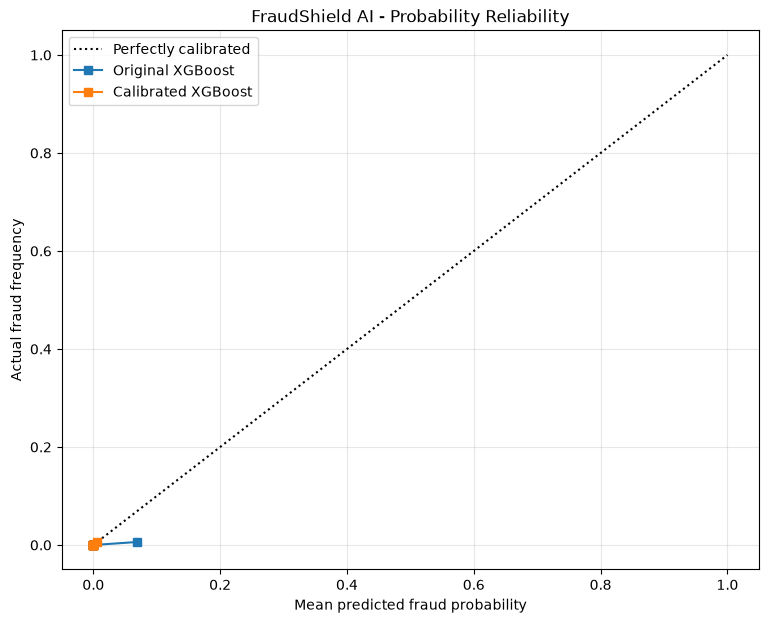

In [41]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(9, 7))

CalibrationDisplay.from_predictions(
    y_calibration_test,
    original_scores,
    n_bins=10,
    strategy="quantile",
    name="Original XGBoost",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_calibration_test,
    calibrated_scores,
    n_bins=10,
    strategy="quantile",
    name="Calibrated XGBoost",
    ax=ax
)

ax.set_title("FraudShield AI - Probability Reliability")
ax.set_xlabel("Mean predicted fraud probability")
ax.set_ylabel("Actual fraud frequency")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [42]:
# Compare probability distributions

probability_summary = pd.DataFrame({
    "Original XGBoost": original_scores,
    "Calibrated XGBoost": calibrated_scores
})

display(
    probability_summary.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    ).T.style.format("{:.8f}")
)

print("\nActual fraud prevalence:")
print(y_calibration_test.mean())

print("\nPredicted average fraud probability:")

print(
    "Original:",
    original_scores.mean()
)

print(
    "Calibrated:",
    calibrated_scores.mean()
)

,count,mean,std,min,50%,90%,95%,99%,99.9%,max
Original XGBoost,490208.00000000,0.00699733,0.05945488,0.00000111,0.00002603,0.00051786,0.00422893,0.20037766,0.90123832,0.99991941
Calibrated XGBoost,490208.00000000,0.00059339,0.01415266,0.00000325,0.00000325,0.00000327,0.00000342,0.00004065,0.21928549,0.49373444



Actual fraud prevalence:
0.0006160650172987793

Predicted average fraud probability:
Original: 0.0069973296
Calibrated: 0.000593391374705266


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define probability ranges suitable for our highly imbalanced dataset
bins = [
    0,
    0.000001,
    0.00001,
    0.0001,
    0.001,
    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    1.0
]

calibration_analysis = pd.DataFrame({
    "Actual": y_calibration_test.to_numpy(),
    "Predicted": calibrated_scores
})

calibration_analysis["Probability Range"] = pd.cut(
    calibration_analysis["Predicted"],
    bins=bins,
    include_lowest=True
)

calibration_table = calibration_analysis.groupby(
    "Probability Range",
    observed=True
).agg(
    Transactions=("Actual", "count"),
    Mean_Predicted_Probability=("Predicted", "mean"),
    Actual_Fraud_Rate=("Actual", "mean"),
    Fraud_Cases=("Actual", "sum")
).reset_index()

display(
    calibration_table.style.format({
        "Mean_Predicted_Probability": "{:.8f}",
        "Actual_Fraud_Rate": "{:.8f}"
    })
)

,Probability Range,Transactions,Mean_Predicted_Probability,Actual_Fraud_Rate,Fraud_Cases
0,"(1e-06, 1e-05]",482639,0.00000330,0.00000000,0
1,"(1e-05, 0.0001]",3568,0.00003109,0.00140135,5
2,"(0.0001, 0.001]",1347,0.00034636,0.00371195,5
3,"(0.001, 0.01]",968,0.00398829,0.01239669,12
4,"(0.01, 0.05]",604,0.02566895,0.02980132,18
5,"(0.05, 0.1]",300,0.07132410,0.04333333,13
6,"(0.1, 0.25]",335,0.15880990,0.03582090,12
7,"(0.25, 0.5]",447,0.43569042,0.53020134,237


In [44]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use calibrated predictions
calibrated_thresholds = np.arange(0.001, 0.501, 0.001)

calibrated_threshold_results = []

for threshold in calibrated_thresholds:

    predictions = (
        calibrated_scores >= threshold
    ).astype(int)

    precision = precision_score(
        y_calibration_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_calibration_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_calibration_test,
        predictions,
        zero_division=0
    )

    calibrated_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

calibrated_threshold_df = pd.DataFrame(
    calibrated_threshold_results
)

# Find best threshold
best_calibrated_threshold = calibrated_threshold_df.loc[
    calibrated_threshold_df["F1 Score"].idxmax()
]

display(
    calibrated_threshold_df.sort_values(
        by="F1 Score",
        ascending=False
    ).head(10).style.format({
        "Threshold": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

print("\nBest calibrated threshold:")
print(best_calibrated_threshold)

,Threshold,Precision,Recall,F1 Score
467,0.468,0.8502,0.6954,0.7650
465,0.466,0.8379,0.7020,0.7640
464,0.465,0.8379,0.7020,0.7640
468,0.469,0.8560,0.6887,0.7633
466,0.467,0.8406,0.6987,0.7631
463,0.464,0.8346,0.7020,0.7626
461,0.462,0.8314,0.7020,0.7612
462,0.463,0.8314,0.7020,0.7612
459,0.460,0.8281,0.7020,0.7599
460,0.461,0.8281,0.7020,0.7599



Best calibrated threshold:
Threshold    0.468000
Precision    0.850202
Recall       0.695364
F1 Score     0.765027
Name: 467, dtype: float64


In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    log_loss
)

import pandas as pd
import numpy as np

# Generate calibrated test probabilities
test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_threshold = 0.468

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Calculate evaluation metrics
final_metrics = {
    "Fraud Prevalence": y_test.mean(),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "F1 Score": f1_score(y_test, test_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "Brier Score": brier_score_loss(y_test, test_probabilities),
    "Log Loss": log_loss(y_test, test_probabilities)
}

print("FRAUDSHIELD AI - FINAL TEST RESULTS")
print("=" * 45)

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.6f}")

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

print("\nConfusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

# Display metrics
final_metrics_df = pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Value"]
)

display(
    final_metrics_df.style.format({
        "Value": "{:.6f}"
    })
)

FRAUDSHIELD AI - FINAL TEST RESULTS
Fraud Prevalence: 0.004361
Precision: 0.967628
Recall: 0.686470
F1 Score: 0.803154
ROC-AUC: 0.999276
PR-AUC: 0.908693
Brier Score: 0.001875
Log Loss: 0.006941

Confusion Matrix:
[[914519     92]
 [  1256   2750]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    914611
       Fraud       0.97      0.69      0.80      4006

    accuracy                           1.00    918617
   macro avg       0.98      0.84      0.90    918617
weighted avg       1.00      1.00      1.00    918617



,Metric,Value
0,Fraud Prevalence,0.004361
1,Precision,0.967628
2,Recall,0.686470
3,F1 Score,0.803154
4,ROC-AUC,0.999276
5,PR-AUC,0.908693
6,Brier Score,0.001875
7,Log Loss,0.006941


In [46]:
# Compare actual and predicted fraud prevalence

actual_test_prevalence = y_test.mean()
predicted_test_prevalence = test_probabilities.mean()

print("TEST SET PROBABILITY RELIABILITY")
print("=" * 45)

print(
    f"Actual fraud prevalence: "
    f"{actual_test_prevalence:.6%}"
)

print(
    f"Average predicted probability: "
    f"{predicted_test_prevalence:.6%}"
)

print(
    f"Difference: "
    f"{abs(actual_test_prevalence - predicted_test_prevalence):.6%}"
)

TEST SET PROBABILITY RELIABILITY
Actual fraud prevalence: 0.436090%
Average predicted probability: 0.206089%
Difference: 0.230002%


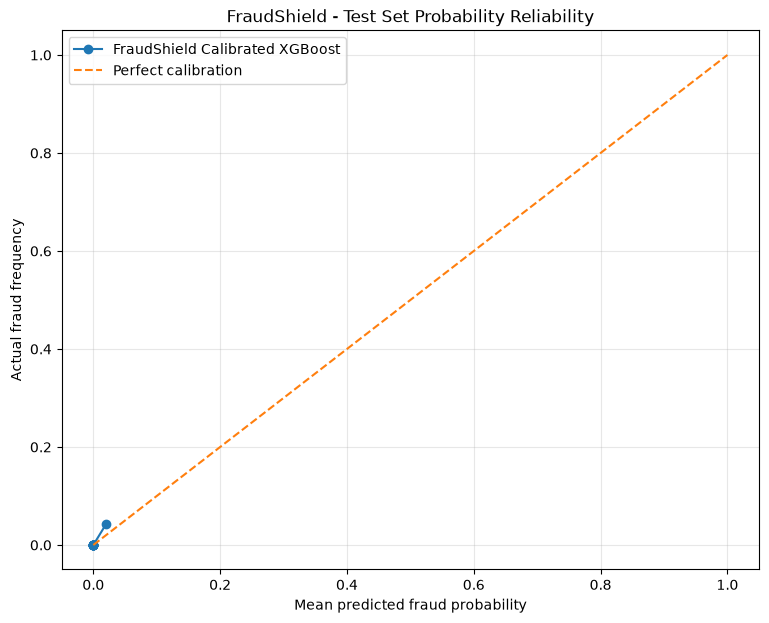

In [47]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

actual_rates, predicted_means = calibration_curve(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(9, 7))

plt.plot(
    predicted_means,
    actual_rates,
    marker="o",
    label="FraudShield Calibrated XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.title("FraudShield - Test Set Probability Reliability")
plt.xlabel("Mean predicted fraud probability")
plt.ylabel("Actual fraud frequency")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [48]:
# Brier score of a simple prevalence-based predictor

prevalence_baseline = np.full(
    len(y_test),
    y_test.mean()
)

baseline_brier = brier_score_loss(
    y_test,
    prevalence_baseline
)

model_brier = brier_score_loss(
    y_test,
    test_probabilities
)

print("TEST BRIER SCORE COMPARISON")
print("=" * 40)

print(f"Baseline Brier Score: {baseline_brier:.8f}")
print(f"Model Brier Score:    {model_brier:.8f}")

print(
    "Improvement:",
    f"{(1 - model_brier / baseline_brier) * 100:.2f}%"
)

TEST BRIER SCORE COMPARISON
Baseline Brier Score: 0.00434189
Model Brier Score:    0.00187482
Improvement: 56.82%


In [49]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Transaction type columns
type_columns = [
    "type_CASH_IN",
    "type_CASH_OUT",
    "type_DEBIT",
    "type_PAYMENT",
    "type_TRANSFER"
]

# Identify the transaction type for each test record
transaction_types = (
    X_test[type_columns]
    .idxmax(axis=1)
    .str.replace("type_", "", regex=False)
)

# Prepare evaluation dataframe
robustness_df = pd.DataFrame({
    "transaction_type": transaction_types,
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "fraud_probability": test_probabilities
})

# Evaluate each transaction category
results = []

for transaction_type, group in robustness_df.groupby("transaction_type"):

    actual = group["actual"]
    predicted = group["predicted"]

    results.append({
        "Transaction Type": transaction_type,
        "Total Transactions": len(group),
        "Actual Fraud Cases": int(actual.sum()),
        "Predicted Fraud Cases": int(predicted.sum()),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        )
    })

transaction_type_results = pd.DataFrame(results)

# Display results
display(
    transaction_type_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

,Transaction Type,Total Transactions,Actual Fraud Cases,Predicted Fraud Cases,Precision,Recall,F1 Score
0,CASH_IN,204069,0,0,0.00%,0.00%,0.00%
1,CASH_OUT,310302,2003,872,99.77%,43.43%,60.52%
2,DEBIT,6588,0,0,0.00%,0.00%,0.00%
3,PAYMENT,317437,0,0,0.00%,0.00%,0.00%
4,TRANSFER,80221,2003,1970,95.43%,93.86%,94.64%


In [50]:
# Create a copy of the test data
amount_robustness = pd.DataFrame({
    "amount": X_test["amount"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "fraud_probability": test_probabilities
})

# Divide transactions into amount groups
amount_robustness["Amount Category"] = pd.qcut(
    amount_robustness["amount"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

# Evaluate each amount category
amount_results = []

for category, group in amount_robustness.groupby(
    "Amount Category", observed=True
):

    actual = group["actual"]
    predicted = group["predicted"]

    amount_results.append({
        "Amount Category": category,
        "Transactions": len(group),
        "Actual Fraud Cases": int(actual.sum()),
        "Detected Fraud": int(
            ((actual == 1) & (predicted == 1)).sum()
        ),
        "Missed Fraud": int(
            ((actual == 1) & (predicted == 0)).sum()
        ),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        )
    })

amount_results_df = pd.DataFrame(amount_results)

display(
    amount_results_df.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

,Amount Category,Transactions,Actual Fraud Cases,Detected Fraud,Missed Fraud,Precision,Recall,F1 Score
0,Low,229655,149,21,128,95.45%,14.09%,24.56%
1,Medium,229654,480,176,304,93.12%,36.67%,52.62%
2,High,229654,662,327,335,94.24%,49.40%,64.82%
3,Very High,229654,2715,2226,489,97.46%,81.99%,89.06%


In [51]:
# Prepare time-based evaluation dataset
time_robustness = pd.DataFrame({
    "step": X_test["step"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "fraud_probability": test_probabilities
})

# Divide test period into five chronological groups
time_robustness["Time Period"] = pd.qcut(
    time_robustness["step"],
    q=5,
    labels=[
        "Period 1",
        "Period 2",
        "Period 3",
        "Period 4",
        "Period 5"
    ],
    duplicates="drop"
)

# Evaluate each period
time_results = []

for period, group in time_robustness.groupby(
    "Time Period", observed=True
):

    actual = group["actual"]
    predicted = group["predicted"]

    time_results.append({
        "Time Period": period,
        "Transactions": len(group),
        "Start Step": int(group["step"].min()),
        "End Step": int(group["step"].max()),
        "Actual Fraud": int(actual.sum()),
        "Detected Fraud": int(
            ((actual == 1) & (predicted == 1)).sum()
        ),
        "Missed Fraud": int(
            ((actual == 1) & (predicted == 0)).sum()
        ),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        )
    })

time_results_df = pd.DataFrame(time_results)

display(
    time_results_df.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

,Time Period,Transactions,Start Step,End Step,Actual Fraud,Detected Fraud,Missed Fraud,Precision,Recall,F1 Score
0,Period 1,190815,379,395,198,138,60,87.34%,69.70%,77.53%
1,Period 2,185680,396,401,88,59,29,78.67%,67.05%,72.39%
2,Period 3,175111,402,422,272,187,85,94.92%,68.75%,79.74%
3,Period 4,185387,423,565,1492,1035,457,97.92%,69.37%,81.21%
4,Period 5,181624,566,743,1956,1331,625,98.23%,68.05%,80.40%


In [52]:
# Separate fraud and legitimate transaction probabilities
fraud_scores = test_probabilities[y_test.to_numpy() == 1]

legitimate_scores = test_probabilities[y_test.to_numpy() == 0]

# Calculate probability distribution statistics
confidence_results = pd.DataFrame({
    "Statistic": [
        "Minimum",
        "25th Percentile",
        "Median",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "99th Percentile",
        "Maximum",
        "Mean"
    ],
    "Fraud Transactions": [
        np.min(fraud_scores),
        np.percentile(fraud_scores, 25),
        np.median(fraud_scores),
        np.percentile(fraud_scores, 75),
        np.percentile(fraud_scores, 90),
        np.percentile(fraud_scores, 95),
        np.percentile(fraud_scores, 99),
        np.max(fraud_scores),
        np.mean(fraud_scores)
    ],
    "Legitimate Transactions": [
        np.min(legitimate_scores),
        np.percentile(legitimate_scores, 25),
        np.median(legitimate_scores),
        np.percentile(legitimate_scores, 75),
        np.percentile(legitimate_scores, 90),
        np.percentile(legitimate_scores, 95),
        np.percentile(legitimate_scores, 99),
        np.max(legitimate_scores),
        np.mean(legitimate_scores)
    ]
})

display(
    confidence_results.style.format({
        "Fraud Transactions": "{:.6f}",
        "Legitimate Transactions": "{:.6f}"
    })
)

,Statistic,Fraud Transactions,Legitimate Transactions
0,Minimum,0.000003,0.000003
1,25th Percentile,0.401889,0.000003
2,Median,0.486810,0.000003
3,75th Percentile,0.493517,0.000003
4,90th Percentile,0.493665,0.000003
5,95th Percentile,0.493683,0.000003
6,99th Percentile,0.493734,0.000038
7,Maximum,0.493734,0.492181
8,Mean,0.386853,0.000375


In [53]:
print("FINAL MODEL VERIFICATION")
print("=" * 45)

print("XGBoost model:", type(best_regularized_model).__name__)

print("Calibrated model:", type(calibrated_model).__name__)

print("Selected threshold:", final_threshold)

print("Number of features:", len(X_train.columns))

print("\nFeatures:")

for feature in X_train.columns:
    print("-", feature)

FINAL MODEL VERIFICATION
XGBoost model: XGBClassifier
Calibrated model: CalibratedClassifierCV
Selected threshold: 0.468
Number of features: 9

Features:
- step
- amount
- oldbalanceOrg
- oldbalanceDest
- type_CASH_IN
- type_CASH_OUT
- type_DEBIT
- type_PAYMENT
- type_TRANSFER


In [54]:
import os
import joblib
import sklearn
import xgboost

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Store model information
metadata = {
    "project": "FraudShield AI",
    "model_name": "XGBoost Fraud Detection Model",
    "algorithm": "XGBoost",
    "calibrated": True,

    "threshold": float(final_threshold),

    "features": list(X_train.columns),

    "hyperparameters": {
        "n_estimators": 300,
        "max_depth": 8,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "scale_pos_weight": float(scale_pos_weight * 2),
        "min_child_weight": 10,
        "reg_lambda": 10,
        "gamma": 2
    },

    "test_metrics": {
        "precision": 0.967628,
        "recall": 0.686470,
        "f1_score": 0.803154,
        "roc_auc": 0.999276,
        "pr_auc": 0.908693,
        "brier_score": 0.001875,
        "log_loss": 0.006941
    },

    "dataset": "PaySim Synthetic Mobile Money Dataset",

    "important_notes": [
        "The dataset is synthetic, not actual M-Pesa transaction data.",
        "Fraud prevalence changed between validation and test periods.",
        "Calibration drift was observed on the test period.",
        "Model predictions should support human investigation, not automatically prove fraud."
    ],

    "versions": {
        "xgboost": xgboost.__version__,
        "scikit_learn": sklearn.__version__
    }
}

# Save original XGBoost model
joblib.dump(
    best_regularized_model,
    "../models/fraudshield_xgboost_model.pkl"
)

# Save calibrated model
joblib.dump(
    calibrated_model,
    "../models/fraudshield_calibrated_model.pkl"
)

# Save metadata
joblib.dump(
    metadata,
    "../models/fraudshield_metadata.pkl"
)

print("MODEL SAVING COMPLETED")
print("=" * 40)
print("Original model saved.")
print("Calibrated model saved.")
print("Metadata saved.")

MODEL SAVING COMPLETED
Original model saved.
Calibrated model saved.
Metadata saved.


In [55]:
import joblib
import numpy as np

# Load saved models
loaded_xgb_model = joblib.load(
    "../models/fraudshield_xgboost_model.pkl"
)

loaded_calibrated_model = joblib.load(
    "../models/fraudshield_calibrated_model.pkl"
)

loaded_metadata = joblib.load(
    "../models/fraudshield_metadata.pkl"
)

# Generate predictions using the loaded calibrated model
loaded_probabilities = (
    loaded_calibrated_model.predict_proba(X_test.iloc[:10])[:, 1]
)

# Compare against the original predictions
original_probabilities = test_probabilities[:10]

print("SAVED MODEL VERIFICATION")
print("=" * 40)

print("Original model loaded:", type(loaded_xgb_model).__name__)
print("Calibrated model loaded:", type(loaded_calibrated_model).__name__)

print("Threshold:", loaded_metadata["threshold"])

print(
    "Predictions match:",
    np.allclose(loaded_probabilities, original_probabilities)
)

print("\nFirst 10 loaded predictions:")
print(loaded_probabilities)

SAVED MODEL VERIFICATION
Original model loaded: XGBClassifier
Calibrated model loaded: CalibratedClassifierCV
Threshold: 0.468
Predictions match: True

First 10 loaded predictions:
[3.24597492e-06 3.27322073e-06 3.24892533e-06 3.24630830e-06
 3.24632798e-06 3.33217387e-06 3.24696003e-06 3.25395607e-06
 3.25055314e-06 3.24612082e-06]
